# Лабораторная работа 1 — рабочий ноутбук

**ФИО:**
**Файлы данных:**

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [192]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

RAW_CLIENTS = "clients.csv"
RAW_TXN = "transactions.csv"

## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

In [193]:
CLIENTS_PATH = "clients.csv"
TXN_PATH     = "transactions.csv"

for path, enc in [(CLIENTS_PATH, "utf-8"), (TXN_PATH, "cp1251")]:
    with open(path, encoding=enc) as f:
        for _ in range(5):
            print(repr(f.readline()))
    print()

'client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in\n'
'C002260,1993-11-03,Ж,ЕКАТЕРИНБУРГ,Массовый,Базовый,Дебетовая,23.09.2022,21.06.2023,Не указан,86200.0,Да,2024-03,,00509,Да\n'
'C004875,1962-08-22,Ж,Москва,Зарплатный,Базовый,Кредитная,04.06.2017,07.05.2021,Зарплата в нашем банке,125900.0,Да,2024-12,,00611,Да\n'
'C004474,1970-02-15,М,Казань,Массовый,Базовый,Дебетовая,20.12.2012,05.04.2016,Зарплата в нашем банке,51700.0,Да,2024-06,2,00829,Нет\n'
'C005867,1986-01-23,Ж,Казань,Зарплатный,Серебро,Дебетовая,25.10.2019,23.10.2023,Зарплата в другом банке,90600.0,Нет,,,00119,Да\n'

'txn_id;client_id;txn_datetime;amount;currency;category;mcc_code;channel;status\n'
'990007;C001947;2023-11-23 09:00:42;823,86;RUB;Продукты;5411;Карта;успешно\n'
'990164;C005366;2023-11-24 14:58:42;68,41;RUB;Транспорт;4111;Карта;успешно\n'
'990056;C005023;2023-11-2

Файл clients.csv читается как UTF-8, разделителем является запятая, дробная часть отделена точкой. 
Даты представлены в разных форматах birth_date - Y-m-d, registration_date и card_open_date - d.m.Y. app_last_login - месяц. client_id - идентификатор,содержащий буквы и branch_code - строка, city - разный регистр. 
transactions.csv читается как cp1251, разделителем является точка с запятой, дробной - запятая. Формат даты - Y-m-d, в txn_datetime гдето-то указана дата без времени, txn_id, client_id, mcc_code - строки идентификаторы.

In [194]:
clients_raw = pd.read_csv(
    CLIENTS_PATH,
    encoding="utf-8",      
    sep=",",
    decimal=".",
    dtype={
        "client_id": "str",     
        "branch_code": "str"
    },
)
clients = clients_raw.copy()
txn_raw = pd.read_csv(
    TXN_PATH,
    encoding="cp1251",
    sep=";",
    decimal=",",                 
    dtype={
        "txn_id": "str",
        "client_id": "str",   
        "mcc_code": "str"
    },
)
txn = txn_raw.copy()

## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

In [195]:
def overview(data):
    return pd.DataFrame({
        "dtype": data.dtypes.astype(str),
        "n_unique": data.nunique(),
        "n_missing": data.isna().sum(),
        "missing_%": (data.isna().mean() * 100).round(2),
        "example": data.iloc[0],
    })
print("Clients")
print('Размер:', clients.shape)
display(overview(clients))
print("Transactions")
print('Размер:', txn.shape)
display(overview(txn))

Clients
Размер: (5694, 16)


,dtype,n_unique,n_missing,missing_%,example
client_id,str,5639,0,0.00,C002260
birth_date,str,4808,0,0.00,1993-11-03
gender,str,2,0,0.00,Ж
city,str,17,0,0.00,ЕКАТЕРИНБУРГ
segment,str,4,0,0.00,Массовый
loyalty_tier,str,4,0,0.00,Базовый
card_type,str,3,0,0.00,Дебетовая
registration_date,str,3235,0,0.00,23.09.2022
card_open_date,str,2642,0,0.00,21.06.2023
income_source,str,3,0,0.00,Не указан


Transactions
Размер: (624130, 9)


,dtype,n_unique,n_missing,missing_%,example
txn_id,str,622630,0,0.0,990007
client_id,str,5991,0,0.0,C001947
txn_datetime,str,567137,0,0.0,2023-11-23 09:00:42
amount,float64,322443,0,0.0,823.86
currency,str,3,0,0.0,RUB
category,str,12,0,0.0,Продукты
mcc_code,str,9,0,0.0,5411
channel,str,4,0,0.0,Карта
status,str,3,0,0.0,успешно


Изучив две таблицы выше, обращаем внимение:
Даты пока представлены в формате строк.
Во второй таблице нет пропусков ни по одному признаку. 
Наблюдается большое количество с признаков с малым количеством уникальных значений, их  тип надо будет изменить на category.
clients_id в таблице клиентов имеет меньше уникальных значений, чем строк, что говорит о возможных дублях или наличии нескольких разных строк для одного клиента, это надо проверить. (то же самое можно сказать о txn_id)
client_id в таблице транзакций  наличие нескольких транзакций у одного клиента логично, однако количестко оригинальный айди клиента больше, чем в таблице клиентов, что говорит о серьезном нарушении целостности данных.
category имеет 12 уникальных значений, когда в описании данных указано 9.
Единицы наблюдения client_id и transaction_id.

### 2.2. Дубли

In [196]:
print("Полных дубликатов строк в clients:", clients.duplicated().sum())
print("повторы client_id =", len(clients) - clients['client_id'].nunique())
print("Полных дубликатов строк в txn:", txn.duplicated().sum())
print("повторы txn_id =", len(txn) - txn['txn_id'].nunique())

Полных дубликатов строк в clients: 40
повторы client_id = 55
Полных дубликатов строк в txn: 1308
повторы txn_id = 1500


Количество полных дубликатов меньше количества не уникальных значений единиц наблюдения в обоих таблицах. Полных дубликатов в обоих таблицах менее одного процента от всех записей. Полные дубликаты в таблице клиенты маловозможны, одинаковые же транзакции теоретически возможны, но тут стоит обратить внимание на столбик txn_id, он должен определять строку однозначно.

### 2.3. Соответствие данных описанию полей из задания

In [197]:
print(txn["category"].value_counts().to_string(), "\n")
domains = {
    "clients": {
        "segment": {"Массовый", "Зарплатный", "Премиальный", "Private"},
        "loyalty_tier": {"Базовый", "Серебро", "Золото", "Платина"},
        "card_type": {"Дебетовая", "Кредитная", "Премиальная"},
    },
    "txn": {
        "channel": {"Карта", "Токен", "СБП", "Онлайн-банк"},
        "status": {"успешно", "отклонено", "возврат"},
    }
}
for tbl_name, tbl in [("clients", clients), ("txn", txn)]:
    for col, exp in domains[tbl_name].items():
        act = set(tbl[col].dropna().unique())
        if act != exp: print(f"{tbl_name}.{col}: Плохо")
        else: print(f"{tbl_name}.{col}: OK")

print("satisfaction_score: min", clients["satisfaction_score"].min(), 
      "| max", clients["satisfaction_score"].max())

txn_dates = pd.to_datetime(txn['txn_datetime'], format='mixed')
print(f"Период операций: {txn_dates.min().date()} .. {txn_dates.max().date()}")

category
Продукты               164942
Транспорт               72396
Одежда и обувь          64242
АЗС                     57338
Кафе и рестораны        48226
Развлечения и досуг     47045
Аптеки                  45461
Онлайн-сервисы          43503
Связь и интернет        29176
Связь и Интернет        19805
Кафе/рестораны          16036
кафе и рестораны        15960 

clients.segment: OK
clients.loyalty_tier: OK
clients.card_type: OK
txn.channel: OK
txn.status: OK
satisfaction_score: min 1.0 | max 5.0
Период операций: 2023-11-23 .. 2026-07-26


Как мы наблюдали выше количество уникальных значений category не совпало с заявленным, смотрим все уникальные значения и видим, что кафе и рестораны трижды записаны по разному, а связь и интернет дважды.
Период операций выходит за пределы заявленного

In [198]:
print(clients['city'].unique())

<StringArray>
[      'ЕКАТЕРИНБУРГ',             'Москва',             'Казань',       'Екатеринбург',          'г. Москва',    'Санкт-Петербург', 'г. Санкт-Петербург',
             'МОСКВА',        'Новосибирск',            ' москва',     'г.Екатеринбург',        'Н. Новгород',             'казань',    'Нижний Новгород',
                'СПб',    'Санкт Петербург',     'г. Новосибирск']
Length: 17, dtype: str


Смотрим на уникальные значения sity, видим, что проблема не только в регистре, одни и те же города записаны по разному, с буквой г. или без, через -, требуется нормализация

### 2.4. Связь между таблицами

In [199]:
ids_in_clients = set(clients['client_id'])
ids_in_txn = set(txn['client_id'])

orphans = ids_in_txn - ids_in_clients
print(f"1. Клиентов в txn, которых нет в clients: {len(orphans)}")
dormant = ids_in_clients - ids_in_txn
print(f"2. Клиентов в clients, у которых нет операций: {len(dormant)}")

temp_map = clients.drop_duplicates('client_id').set_index('client_id')['card_open_date']
card_dates = txn['client_id'].map(temp_map)
txn_dates = pd.to_datetime(txn['txn_datetime'], format='mixed')
card_dates = pd.to_datetime(card_dates, format='%d.%m.%Y')
print("3. Операций раньше открытия карты:", (txn_dates < card_dates).sum())

txn['txn_datetime'].str.len().value_counts()

1. Клиентов в txn, которых нет в clients: 361
2. Клиентов в clients, у которых нет операций: 9
3. Операций раньше открытия карты: 1


txn_datetime
19    574042
10     50088
Name: count, dtype: int64

**Выводы по аудиту.** Перечислите найденное: что это, сколько строк,
насколько это мешает решить задачу.

В clients найдено 40 дублей (55 по client_id), в txn - 1308 (1500 по txn_id).Требует очистки, чтобы не использовать одни и те же данные дважды.
361 клиент совершает операции, но не существует, нарушена целостность данных. 9 клиентов есть в справочнике, но не имеют операций, надо проверить, возможно это просто новые клиенты, а не призраки. Найдена 1 операция до открытия карты. В sity встречаются разные записи одних  и тех  же, по количеству уникальных значений 17 понимаем, что признак категориальный, надо нормализовать регистры и вид записи, чтобы избежать дублей категорий.
В txn.category 12 значений вместо заявленных 9 из-за разного написания, нужна нормализация, без которой оценить вклад категорий не получится. 
Период совершения операций выходит за пределы заявленного, в txn_datetime встречаются даты со временем и без около 50 тысяч строк.

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

In [200]:
rows_clients_before = len(clients)
rows_txn_before = len(txn)

clients = clients.drop_duplicates().reset_index(drop=True)
txn = txn.drop_duplicates().reset_index(drop=True)

deleted_clients = rows_clients_before - len(clients)
deleted_txn = rows_txn_before - len(txn)

print(f"Удалено дублей в clients: {deleted_clients}")
print(f"Удалено дублей в txn: {deleted_txn}")

Удалено дублей в clients: 40
Удалено дублей в txn: 1308


Чистим полные дубли

### 3.1. Типы, даты, числа

In [201]:
na_before = clients[['birth_date', 'registration_date', 'card_open_date', 'app_last_login']].isna().sum()
clients['birth_date'] = pd.to_datetime(clients['birth_date'], format='%Y-%m-%d', errors='coerce')
clients['registration_date'] = pd.to_datetime(clients['registration_date'], format='%d.%m.%Y', errors='coerce')
clients['card_open_date'] = pd.to_datetime(clients['card_open_date'], format='%d.%m.%Y', errors='coerce')
clients['app_last_login'] = pd.to_datetime(clients['app_last_login'], format='%Y-%m', errors='coerce')

na_after = clients[['birth_date', 'registration_date', 'card_open_date', 'app_last_login']].isna().sum()
print("Новые NaTв clients:")
print(na_after - na_before)

na_before = txn['txn_datetime'].isna().sum()
txn['txn_datetime'] = pd.to_datetime(txn['txn_datetime'], format='mixed', errors='coerce')
na_after = txn['txn_datetime'].isna().sum()

print("txn_datetime ", na_after - na_before)

Новые NaTв clients:
birth_date           0
registration_date    0
card_open_date       0
app_last_login       0
dtype: int64
txn_datetime  0


### 3.2. Категориальные признаки

In [202]:
original_cat = txn['category'].copy()
txn['category'] = txn['category'].replace({
    'Кафе/рестораны': 'Кафе и рестораны',
    'кафе и рестораны': 'Кафе и рестораны',
    'Связь и Интернет': 'Связь и интернет'
})
n_changed_cat = (original_cat != txn['category']).sum()
print(f"Строк в category изменено: {n_changed_cat}")
original_city = clients['city'].copy()
city_clean = clients['city'].str.lower().str.strip().str.replace(r'^г\.\s*', '', regex=True)

city_clean = city_clean.replace({
    'спб': 'санкт-петербург',
    'санкт петербург': 'санкт-петербург',
    'н. новгород': 'нижний новгород'
})
clients['city'] = city_clean.str.title()
n_changed_city = (original_city != clients['city']).sum()
print(f"Строк в city изменено: {n_changed_city}")

Строк в category изменено: 51687
Строк в city изменено: 1669


In [203]:
cat_cols_cli = ['gender', 'city', 'segment', 'loyalty_tier', 'card_type', 'income_source', 'has_mobile_app', 'satisfaction_score', 'marketing_opt_in']
clients[cat_cols_cli] = clients[cat_cols_cli].astype('category')

cat_cols_txn = ['currency', 'category', 'mcc_code', 'channel', 'status']
txn[cat_cols_txn] = txn[cat_cols_txn].astype('category')


### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

In [204]:

missing = clients.isna().mean() * 100
print("Доля пропусков (%):")
print(missing[missing > 0].round(2), "\n")

Доля пропусков (%):
monthly_income         8.88
app_last_login        38.01
satisfaction_score    59.52
dtype: float64 



In [205]:
print("Пропуски в app_last_login по наличию приложения:")
print(clients.groupby('has_mobile_app')['app_last_login'].apply(lambda x: x.isna().mean() * 100).round(2), "\n")

Пропуски в app_last_login по наличию приложения:
has_mobile_app
Да       0.0
Нет    100.0
Name: app_last_login, dtype: float64 



In [206]:
print("Пропуски в monthly_income по источнику дохода:")
print(clients.groupby('income_source')['monthly_income'].apply(lambda x: x.isna().mean() * 100).round(2))

Пропуски в monthly_income по источнику дохода:
income_source
Зарплата в другом банке     2.71
Зарплата в нашем банке      3.37
Не указан                  25.15
Name: monthly_income, dtype: float64


In [207]:
print("Доля ПРОПУСКОВ в satisfaction_score по наличию приложения (%):")
print(clients.groupby('has_mobile_app')['satisfaction_score'].apply(lambda x: x.isna().mean() * 100).round(1), "\n")

month_login = clients['app_last_login'].dt.to_period('M').astype(str).replace('NaT', 'Нет входа')

print("Доля ПРОПУСКОВ в satisfaction_score по месяцу последнего входа (%):")
print(clients.groupby(month_login)['satisfaction_score'].apply(lambda x: x.isna().mean() * 100).round(1).sort_index())

Доля ПРОПУСКОВ в satisfaction_score по наличию приложения (%):
has_mobile_app
Да     59.5
Нет    59.6
Name: satisfaction_score, dtype: float64 

Доля ПРОПУСКОВ в satisfaction_score по месяцу последнего входа (%):
app_last_login
2024-01    56.4
2024-02    57.1
2024-03    60.5
2024-04    57.7
2024-05    57.7
2024-06    54.5
2024-07    61.3
2024-08    60.0
2024-09    57.5
2024-10    57.1
2024-11    58.9
2024-12    62.9
2025-01    60.7
2025-02    65.2
2025-03    65.5
2025-04    56.4
2025-05    59.2
2025-06    61.4
Name: satisfaction_score, dtype: float64


Видим, что дата последнего входа в приложение пропущена исключительно у клиентов, не зарегестрированных в приложении, значит, пропуски логичны, их не нужно заполнять. А доход не указан в основном у людей, не указавших источник дохода, эти два столбика связаны логически, поэтому заполнять будем медианой групп, определенных категориями столбика источника дохода. Оценку качества обслуживания не заполнили почти 60% пользователей, что крайне много, чтобы заполнять их по медиане или другим способом, также мы посмотрели, есть ли связь между месяцем последнего входа (наличием приложения) и наличием оценки, связи не наблюдается. Заполнять эти пропуски не будем, но поставим флажок на клиентах, кто прошел опрос, а кто нет

In [208]:
n_missing_income = clients['monthly_income'].isna().sum()
print(f"Изменено: {n_missing_income} строк")
income_median_by_group = clients.groupby('income_source', observed=True)['monthly_income'].transform('median')
clients['monthly_income'] = clients['monthly_income'].fillna(income_median_by_group)


Изменено: 502 строк


In [209]:
clients['is_surveyed'] = clients['satisfaction_score'].notna().astype(int)
print(f"Прошли опрос: {clients['is_surveyed'].sum()} из {len(clients)}")

Прошли опрос: 2289 из 5654


### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

In [210]:
current_date = pd.Timestamp('2025-06-30')
clients['age'] = (current_date - clients['birth_date']).dt.days // 365

print(f"Клиентов младше 18 лет: {(clients['age'] < 18).sum()}")
print(f"Клиентов старше 100 лет: {(clients['age'] > 100).sum()}")

display(clients['monthly_income'].quantile([0, 0.01, 0.25, 0.5, 0.75, 0.99, 0.999, 1]).to_frame().T.round(2))
display(txn['amount'].quantile([0, 0.01, 0.25, 0.5, 0.75, 0.99, 0.999, 1]).to_frame().T.round(2))

Клиентов младше 18 лет: 0
Клиентов старше 100 лет: 0


,0.000,0.010,0.250,0.500,0.750,0.990,0.999,1.000
monthly_income,-999.0,42.16,54200.0,69900.0,103600.0,451599.0,810337.1,1027300.0


,0.000,0.010,0.250,0.500,0.750,0.990,0.999,1.000
amount,-73468.97,-297.65,451.1,1047.45,2225.54,12742.79,26704.73,118240.88


Проверяем, что нет выбросов по возрасту клиентов, а также рассматривам два признака, в которых могут быть выбросы. Обращаем внимание на минимальный доход, он отрицательный, такого быть не может, число -999 может быть маркером отсутствия данных проверим, сколько таких строк. Минимальная сумма транзакций тоже отрицательная, но выдает более адекватное число, также видим, что 1% данных все еще остается отрицательным, более того число после минуса меняется. В банковских выгрузках принято, что отрицательная сумма операции - это возврат, проверим зависит ли отрицательность суммы транзакции от столбика status. 

In [211]:
n_minus_999 = (clients['monthly_income'] == -999).sum()
print(f"Строк со значением -999 в monthly_income: {n_minus_999}")

Строк со значением -999 в monthly_income: 39


In [212]:
print(txn[txn['amount'] < 0]['status'].value_counts())

status
возврат      7478
отклонено       0
успешно         0
Name: count, dtype: int64


Видим, что клиентов с отрицательным доходом немного, принимаем их как не указание уровня дохода, будем заполнять также как пропуски в этом же столбце ранее, при помощи медианы в группах по источнику дохода. Видим, что все отрицательные значения в сумме опереций это возврат, это не выбросы.


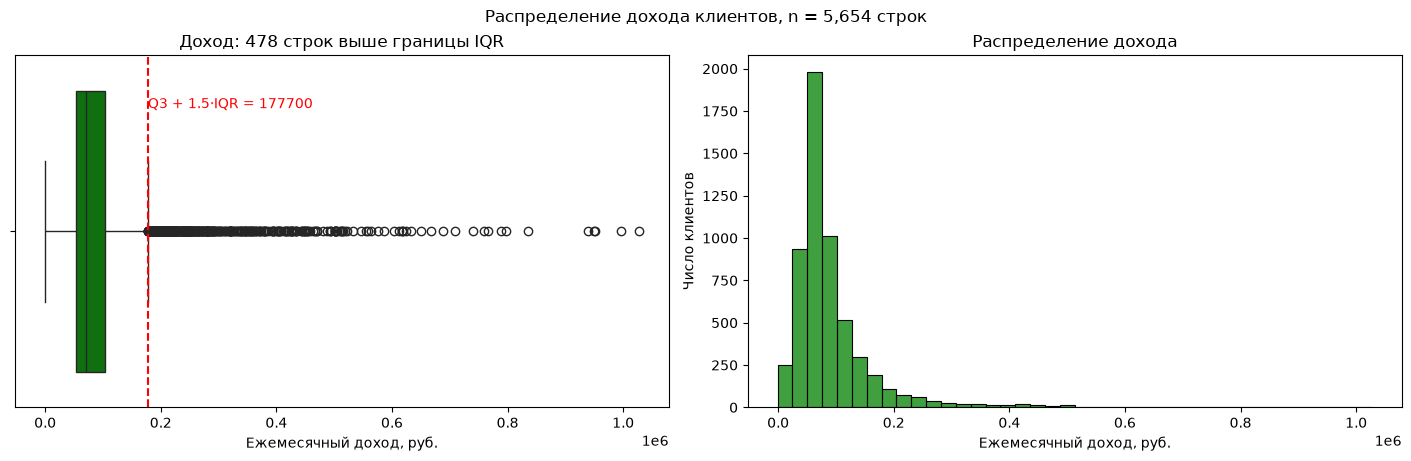

In [213]:
q = clients["monthly_income"]
q1, q3 = q.quantile([0.25, 0.75])
upper_iqr = q3 + 1.5 * (q3 - q1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), layout="constrained")

sns.boxplot(x=q, ax=axes[0], color="green")
axes[0].axvline(upper_iqr, color="red", ls="--")
axes[0].annotate(f"Q3 + 1.5·IQR = {upper_iqr:.0f}", xy=(upper_iqr, -0.35), color="red")
axes[0].set_title(f"Доход: {(q > upper_iqr).sum()} строк выше границы IQR")
axes[0].set_xlabel("Ежемесячный доход, руб.")

sns.histplot(clients["monthly_income"], bins=40, ax=axes[1], color="green")
axes[1].set_title("Распределение дохода")
axes[1].set_xlabel("Ежемесячный доход, руб.")
axes[1].set_ylabel("Число клиентов")

fig.suptitle(f"Распределение дохода клиентов, n = {len(clients):,} строк")
plt.show()

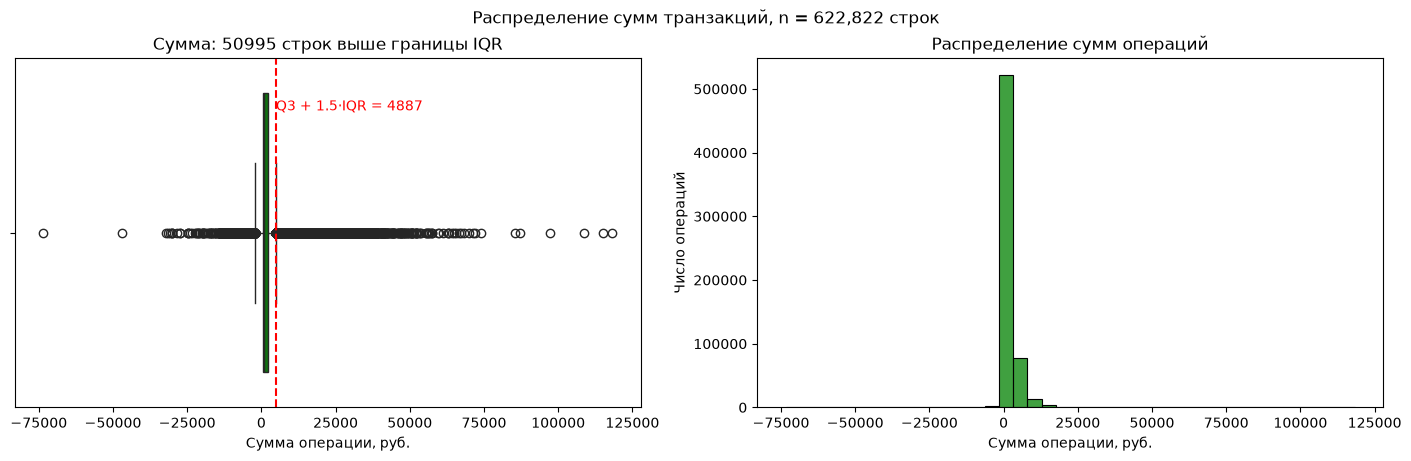

In [214]:
q = txn["amount"]
q1, q3 = q.quantile([0.25, 0.75])
upper_iqr = q3 + 1.5 * (q3 - q1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), layout="constrained")

sns.boxplot(x=q, ax=axes[0], color="green")
axes[0].axvline(upper_iqr, color="red", ls="--")
axes[0].annotate(f"Q3 + 1.5·IQR = {upper_iqr:.0f}", xy=(upper_iqr, -0.35), color="red")
axes[0].set_title(f"Сумма: {(q > upper_iqr).sum()} строк выше границы IQR")
axes[0].set_xlabel("Сумма операции, руб.")

sns.histplot(txn["amount"], bins=40, ax=axes[1], color="green")
axes[1].set_title("Распределение сумм операций")
axes[1].set_xlabel("Сумма операции, руб.")
axes[1].set_ylabel("Число операций")

fig.suptitle(f"Распределение сумм транзакций, n = {len(txn):,} строк")
plt.show()

Изучаем гистограммы и ящики с усами, видим хвосты справа в обеих ситуациях, однако большой доход или крупная операция это не всегда выброс, делаем доп проверку: доход по статусу клиента и сумма транзакции по категории траты

In [228]:
outliers_income = clients[clients['monthly_income'] > upper_iqr_income]

print("Распределение сегментов среди клиентов с доходом выше IQR (%):")
print((outliers_income['segment'].value_counts(normalize=True) * 100).round(1))

Распределение сегментов среди клиентов с доходом выше IQR (%):
segment
Премиальный    51.2
Private        42.3
Зарплатный      5.0
Массовый        1.5
Name: proportion, dtype: float64


In [234]:
suspicious_income = clients[
    (clients['monthly_income'] > upper_iqr_income) & 
    (clients['segment'].isin(['Массовый', 'Зарплатный']))
]

print(f"Всего таких клиентов: {len(suspicious_income)}")
display(suspicious_income[['client_id', 'segment', 'monthly_income', 'income_source', 'card_type']].sort_values('monthly_income', ascending=False).head(10))

Всего таких клиентов: 31


,client_id,segment,monthly_income,income_source,card_type
2172,C004151,Зарплатный,434100.0,Зарплата в нашем банке,Кредитная
791,C005823,Зарплатный,249700.0,Зарплата в нашем банке,Кредитная
2729,C003856,Зарплатный,246600.0,Зарплата в нашем банке,Дебетовая
937,C005858,Массовый,240000.0,Зарплата в другом банке,Дебетовая
4764,C003206,Зарплатный,221100.0,Зарплата в нашем банке,Кредитная
4509,C000865,Зарплатный,218700.0,Зарплата в нашем банке,Дебетовая
2068,C000553,Массовый,216800.0,Не указан,Дебетовая
33,C003494,Зарплатный,211400.0,Зарплата в нашем банке,Кредитная
4107,C005095,Зарплатный,206600.0,Зарплата в нашем банке,Кредитная
2945,C003824,Зарплатный,205900.0,Зарплата в нашем банке,Дебетовая


Видим, что клиенты с высоким доходом являются приватными или преальными, их высокий доход абсолютно логичен и не является выбросом. Есть также клиенты статуса зарплатный или массовый с высоким доходом, надо проверить дополнительно, смотрим на время нахождения в банке, источник дохода, количество операций и сумму трат. Сравниваем сумму трат с ежемесячным доходом и выводим только тех клиентов, которые зарабатывают в месяц больше, чем потратили за все время в банке

In [243]:
current_date = pd.Timestamp('2025-06-30')
suspicious_income = suspicious_income.copy()
suspicious_income['days_in_bank'] = (current_date - suspicious_income['registration_date']).dt.days

txn_success = txn[txn['status'] == 'успешно']
suspicious_txn = txn_success[txn_success['client_id'].isin(suspicious_income['client_id'])]

txn_stats = suspicious_txn.groupby('client_id').agg(
    total_spent=('amount', 'sum'),
    txn_count=('txn_id', 'count'),
    avg_check=('amount', 'mean')
).reset_index()

check_31 = suspicious_income.merge(txn_stats, on='client_id', how='left').fillna({'total_spent': 0, 'txn_count': 0})

check_31 = check_31.sort_values('total_spent', ascending=False).reset_index(drop=True)

check_31_filtered = check_31[check_31['monthly_income'] > check_31['total_spent']]

print(f"Из {len(check_31)} клиентов, у {len(check_31_filtered)} доход в месяц больше трат за весь период:")

display(check_31_filtered[['client_id', 'segment', 'income_source', 'monthly_income', 'days_in_bank', 'txn_count', 'total_spent']])

Из 31 клиентов, у 13 доход в месяц больше трат за весь период:


,client_id,segment,income_source,monthly_income,days_in_bank,txn_count,total_spent
8,C004151,Зарплатный,Зарплата в нашем банке,434100.0,993,126,324860.44
19,C003856,Зарплатный,Зарплата в нашем банке,246600.0,950,77,220819.62
20,C003262,Зарплатный,Зарплата в нашем банке,187400.0,3633,105,183435.35
21,C005664,Массовый,Зарплата в другом банке,188100.0,3670,85,182430.70
22,C001343,Зарплатный,Зарплата в нашем банке,193700.0,3403,69,166544.11
23,C003494,Зарплатный,Зарплата в нашем банке,211400.0,2703,83,160643.59
24,C001486,Зарплатный,Не указан,190300.0,5065,58,130065.95
25,C000178,Массовый,Не указан,192500.0,1911,57,102415.17
26,C005528,Зарплатный,Зарплата в нашем банке,187100.0,2801,48,72181.77
27,C000553,Массовый,Не указан,216800.0,4328,40,68605.54


10 клиентов - активные пользователи. Совершили от 40 до 126 операций на суммы от 68 до 324 тыс. руб. Их доход логично подтверждается активностью трат.
3 клиента имеют длительное пребывание в банке(от 254 до 2103 дней) и высокий доход (180-190 тыс.), но совершили всего от 1 до 5 операций. Однако у всех троих источник дохода - "Зарплата в нашем банке". Это доказывает, что ошибки ввода нет, просто клиенты получают зарплату в банке, но тратят ее через другие каналы.

In [233]:

outliers_txn = txn_seg[txn_seg['amount'] > upper_iqr_amount]
print(outliers_txn['category'].value_counts().head(5))

category
Одежда и обувь         26916
Развлечения и досуг     9499
АЗС                     5711
Кафе и рестораны        5462
Продукты                2837
Name: count, dtype: int64


Проверили категории трат у больших транзакций, в них действительно можно потратить много, так что это не выбросы

In [215]:
clients.loc[clients['monthly_income'] == -999, 'monthly_income'] = np.nan
income_median_by_group = clients.groupby('income_source', observed=True)['monthly_income'].transform('median')
clients['monthly_income'] = clients['monthly_income'].fillna(income_median_by_group)

### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [216]:
cleaning_log = pd.DataFrame(columns=[
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
])

In [217]:
new_logs_duplicates = [
    {
        "field": "client_id", 
        "issue": "полные дубли строк", 
        "scope": "clients", 
        "n_rows": deleted_clients, 
        "value_before": "дубликаты", 
        "action": "удалено", 
        "value_after": "уникальные строки", 
        "rationale": "технические дубли выгрузки, искажают статистику и метрику"
    },
    {
        "field": "txn_id", 
        "issue": "полные дубли строк", 
        "scope": "txn", 
        "n_rows": deleted_txn, 
        "value_before": "дубликаты", 
        "action": "удалено", 
        "value_after": "уникальные строки", 
        "rationale": "технические дубли выгрузки, приводили к двойному счету операций"
    }
]

cleaning_log = pd.concat([cleaning_log, pd.DataFrame(new_logs_duplicates)], ignore_index=True)

In [218]:
new_logs = [
    {
        "field": "txn_datetime", "issue": "строковый формат (с временем и без)",
        "scope": "transactions", "n_rows": len(txn),
        "value_before": "str ('2023-11-23 09:00:42', '2023-11-26')", "action": "конвертация",
        "value_after": "datetime64", "rationale": "для корректного расчета периодов"
    },
    {
        "field": "txn_datetime, birth_date, registration_date, card_open_date, app_last_login", 
        "issue": "строковый формат на датах", "scope": "clients", "n_rows": len(clients),
        "value_before": "str ('1993-11-03', '23.09.2022', '2024-03')", "action": "конвертация",
        "value_after": "datetime64", "rationale": "для расчета возраста, стажа и давности входа"
    }
]

cleaning_log = pd.concat([cleaning_log, pd.DataFrame(new_logs)], ignore_index=True)

In [219]:
new_logs2 = [
    {
        "field": "category", 
        "issue": "разнобой в написании, 12 уникальных значений вместо 9", 
        "scope": "txn", 
        "n_rows": 51687,  
        "value_before": "'Кафе/рестораны', 'кафе и рестораны', 'Связь и Интернет'", 
        "action": "исправлено", 
        "value_after": "9 уникальных категорий", 
        "rationale": "устранение дублей категорий"
    },
    {
        "field": "city", 
        "issue": "разный регистр, приставки, сокращения (17 вариантов)", 
        "scope": "clients", 
        "n_rows": 1669, 
        "value_before": "'г. Москва', ' москва', 'СПб', 'ЕКАТЕРИНБУРГ'", 
        "action": "нормализация", 
        "value_after": "6 городов", 
        "rationale": "устранение дублей категорий"
    },
    {
        "field": "cat_cols (segment, city, category и др.)", 
        "issue": "неоптимальный тип данных для полей с малым числом уникальных значений", 
        "scope": "clients, txn", 
        "n_rows": len(clients) + len(txn), 
        "value_before": "str", 
        "action": "изменение типа", 
        "value_after": "category", 
        "rationale": "экономия оперативной памяти"
    }
]
cleaning_log = pd.concat([cleaning_log, pd.DataFrame(new_logs2)], ignore_index=True)

In [220]:
new_log_33_app_login = [{
    "field": "app_last_login", 
    "issue": "пропуски 38.01%", 
    "scope": "clients", 
    "n_rows": 2149, 
    "value_before": "NaN", 
    "action": "оставлено", 
    "value_after": "NaN", 
    "rationale": "пропуск неслучаен, клиент не имеет приложения или ни разу не заходил"
}]

cleaning_log = pd.concat([cleaning_log, pd.DataFrame(new_log_33_app_login)], ignore_index=True)

In [221]:
new_logs3 = [ {
        "field": "monthly_income", "issue": "пропуски 8.88%", "scope": "clients", 
        "n_rows": 502, "value_before": "NaN", 
        "action": "заполнение", "value_after": "медиана по группам income_source", 
        "rationale": "зависимость от источника дохода"
    }]
cleaning_log = pd.concat([cleaning_log, pd.DataFrame(new_logs3)], ignore_index=True)

In [222]:
new_logs_33_score = [{
    "field": "satisfaction_score", 
    "issue": "пропуски 59.52%", 
    "scope": "clients", 
    "n_rows": 3365, 
    "value_before": "NaN", 
    "action": "создан флаг", 
    "value_after": "NaN, колонка is_surveyed", 
    "rationale": "заполнение 60% данных исказит распределение, факт отсутствия оценки сохранен как отдельный признак"
}]
cleaning_log = pd.concat([cleaning_log, pd.DataFrame(new_logs_33_score)], ignore_index=True)

In [223]:
new_log_34 = [{
    "field": "monthly_income", 
    "issue": "техническое значение -999 (маркер отсутствия данных)", 
    "scope": "clients", 
    "n_rows": 39, 
    "value_before": "-999.0", 
    "action": "заменено на NaN и заполнено медианой по группам", 
    "value_after": "медиана по группам income_source", 
    "rationale": "доход не может быть отрицательным"
}]

cleaning_log = pd.concat([cleaning_log, pd.DataFrame(new_log_34)], ignore_index=True)

In [224]:
new_log_34_refunds = [{
    "field": "amount", 
    "issue": "отрицательные значения (до -73k)", 
    "scope": "txn", 
    "n_rows": 7478, 
    "value_before": "отрицательные суммы", 
    "action": "оставлено", 
    "value_after": "без изменений", 
    "rationale": "все 7488 строк соответствуют статусу 'возврат' (особенность учета)"
}]
cleaning_log = pd.concat([cleaning_log, pd.DataFrame(new_log_34_refunds)], ignore_index=True)

In [244]:
new_log_34_outliers = [{
    "field": "monthly_income", 
    "issue": "выбросы выше границы IQR", 
    "scope": "clients", 
    "n_rows": 485, 
    "value_before": "> 177 700 руб.", 
    "action": "оставлено", 
    "value_after": "без изменений", 
    "rationale": "Основная часть в статусе Премиум/Private. Остальные проверены по сумме трат и количеству операций"
}]

cleaning_log = pd.concat([cleaning_log, pd.DataFrame(new_log_34_outliers)], ignore_index=True)

In [245]:
new_log_34_txn_outliers = [{
    "field": "amount", 
    "issue": "выбросы выше границы IQR", 
    "scope": "txn", 
    "n_rows": 51086, 
    "value_before": "> 4886 руб.", 
    "action": "оставлено", 
    "value_after": "без изменений", 
    "rationale": "Крупные суммы распределены по логичным категориям (Одежда и обувь, Развлечения, АЗС, Кафе), что подтверждает реальность трат."
}]

cleaning_log = pd.concat([cleaning_log, pd.DataFrame(new_log_34_txn_outliers)], ignore_index=True)

## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

### 5.1. Распределения количественных признаков

### 5.2. Частотные характеристики категориальных признаков

### 5.3. Динамика по месяцам

### 5.4. Разрезы и связи между признаками

## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

### 7.1. Кого в кампанию не берём и почему

## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [225]:
# clean.to_parquet("clean_data.parquet", index=False)
# cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
# campaign[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")